# 09: Reading a global fit's storage files

**This notebook targets the development stack (LATW `dev` branch).** It reads the storage files of an
installed stock global fit with the development LISA Analysis Tools packages
(`lisa-analysis-tools/install.sh`), not the pip releases.

```bash
git clone https://github.com/lisa-analysis-tools/lisa-analysis-tools.git
bash lisa-analysis-tools/install.sh
```

If the install fails, see the [installation documentation](https://lisa-analysis-tools.github.io/lisa-analysis-tools).
The most likely problem is LAPACK or a similar system library.

If you hit runtime problems, pin the thread counts before the imports:

```python
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
           "VECLIB_MAXIMUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ.setdefault(_v, "1")
```

In [1]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import lisatools
from lisatools.domains import WDMSignal, TDSettings, WDMSettings, WDMLookupTable
from lisatools.analysiscontainer import AnalysisContainer, AnalysisContainerArray
from lisatools.globalfit.hdfbackend import (GFHDFBackend, GBHDFBackend, ModuleSubBackend,
                                            MBHHDFBackend, EMRIHDFBackend, SOBBHHDFBackend)
from lisatools.sensitivity import (CompositeSensitivityBackend, UnequalArmInstrumentNoise,
                                   UnequalArmXX2TDISens, LinkDelayTable, GalForTimeModulation)
from lisatools.globalfit.stock.erebor.noise import (read_noise_model_identity, resolve_noise_file,
                                                    make_galfor_log_transform_container)
from lisatools.detector import L1Orbits
from lisatools.wdm_lookup_store import lookup_table_path, resolve_gb_lookup_table
from lisatools.sources.bbh import PhenomTHMTDIWaveform
from lisatools.sources.emri import emri_catalogue_to_waveform_basis
from lisatools.sources.emri.response import (EMRI_INSPIRAL_KWARGS, EMRI_SUM_KWARGS,
                                             EMRI_MODE_SELECTOR_KWARGS)
from lisatools.sources.emri.wdm_direct import EMRIDirectWDM
from lisatools.sources.emri.direct_signal_gen import EMRIDirectWDMSignalGen
from lisatools.sources.sobbh.wdm_direct import SOBBHLookupComputations
from lisatools.response.tdiconfig import TDIConfig
from lisatools.globalfit.recipe import MOJITO_REFERENCE_TIME, gb_catalogue_to_sampling_basis
from lisatools.globalfit.moves.sobbhspecialmove import SOBBHChunkedLikeMove
from lisatools.globalfit.stock.erebor.vgb import load_vgb_catalogue_file
from lisatools.globalfit.stock.erebor.transforms import (
    make_gb_transform_container, make_mbh_transform_container,
    make_sobbh_transform_container, make_emri_transform_container)
from gbgpu.gblookupcomputations import GBLookupWDMComputations
from gbgpu.gbsignalhetcomputations import GBSignalHetComputations
from few.waveform.waveform import GenerateEMRIWaveform

No CuPy


In this tutorial we read the output files of a global-fit run, such as our recent CD1-L runs: the
stored samples of every branch, the run's residual, and the noise model the samples are scored
against. Nothing here builds or runs a fit; it is all postprocessing of files a run has already
written.

A run writes one HDF5 **store**, `<base>_testing.h5` (the `_testing` suffix is a legacy name and may
change). For every saved iteration (a **row**) it holds each branch's **cold chain** (the
temperature-1 walkers): the parameters of every source, which sources are alive (`inds`), and each
walker's joint log-likelihood. Each branch also has a **sub-backend** group in the same file with its
**tempered ensemble** (every rung of its temperature ladder) and its sampler counters. Beside the
store the run writes a **residual snapshot**, `<base>_testing_residual_snapshot.npz`: the data minus
every fitted signal, for every cold walker, at one row.

A production run has seven branches: `gb`, `vgb`, `psd`, `galfor`, `mbh`, `emri`, `sobbh`. The files
come from the cluster in the run's output-data tar (next). The store in it is a reduced copy,
`<base>_testing_extract.h5`, which reads like the full store for what it keeps. Either works below.

### Getting a run's output

On the cluster build the data tar of a run folder:

```bash
python -m lisatools.globalfit.monitor RUN_DIR --output-data -v
```

It writes `RUN_DIR_output_data.tar.gz` beside the run folder in a few minutes (`-v` lists what it ships;
on a shared filesystem add `HDF5_USE_FILE_LOCKING=FALSE`). The tar holds the data this notebook reads: the store extract, the residual snapshot that matches the extract, and the run folder's WDM lookup
tables (`wdm_lookup_*.h5`), which the GB, SOBBH and EMRI templates are built from. On a live run the
builder waits for a snapshot whose log-likelihoods equal the stored row it names, and pins the extract
to the rows stored at that moment, so the two always belong together.

Unpack it where the notebook can see it, and point `run_dir` below at the folder it creates:

```bash
tar -xzf gf_prod_9mo_v9_output_data.tar.gz -C /path/to/gf_output/
ls /path/to/gf_output/gf_prod_9mo_v9/
# gf_prod_9mo_testing_extract.h5  gf_prod_9mo_testing_residual_snapshot.npz  wdm_lookup_*.h5
```

The notebook also needs the mojito data folder the run was built from (`mojito_dir`, in the psd
section): its L1 NOISE brick gives the orbits and the link delays of the noise model, and its
`catalogues/` the fixed parameters of the VGB and EMRI sources.

### Documentation

The classes used here are documented. The
`dev` branch's sites are not online; build them locally as described in LAT's
[`docs/browsing-docs-locally.md`](https://github.com/lisa-analysis-tools/lisa-analysis-tools/blob/dev/docs/browsing-docs-locally.md)
(`sphinx-build -M html docs/source docs/build -j 1` in each repo, a few minutes each) and open
`<repo>/docs/build/html/index.html`. Where each class lives, as pages under `docs/build/html/`; every
entry is anchored by its dotted name, e.g. `user/globalfit.html#lisatools.globalfit.hdfbackend.GFHDFBackend`:

| classes | package | page |
|---|---|---|
| `GFHDFBackend`, the sub-backend readers, `GFState` | lisatools | `user/globalfit.html`; the residual snapshot: `user/globalfit_internals.html`; the monitor and the output-data tar: `user/globalfitmonitor.html` |
| `WDMSettings`, `WDMSignal`, `WDMLookupTable` | lisatools | `user/domains.html` |
| `CompositeSensitivityBackend`, `UnequalArmInstrumentNoise`, `LinkDelayTable`, `GalForTimeModulation` | lisatools | `user/sensitivity.html`; the foreground spectrum: `user/stochastic.html` |
| `L1Orbits` | lisatools | `user/detector.html` |
| `AnalysisContainer` | lisatools | `user/datacontainer.html` |
| the stock transforms (`make_*_transform_container`), the noise-model identity | lisatools | `user/globalfitstock.html` |
| `PhenomTHMTDIWaveform`, `SOBBHLookupComputations`, `EMRIDirectWDM`, `EMRIDirectWDMSignalGen` | lisatools | `user/sources.html` |
| `GBWDMComputations`, `GBSignalHetComputations`, `GBLookupComputations` | gbgpu | `user/computations.html`; the production GB likelihood chain: `user/likelihood_path.html` |
| `GenerateEMRIWaveform`, `FastKerrEccentricEquatorialFlux` | few | `user/main.html` |

The store's layout is also described in LAT's `docs/conventions.md` ("Global-fit storage") and
`docs/global-fit-navigation.md`.

## The store and its residual

Set `store` and `snapshot` to your run's files. Open the store with `GFHDFBackend` and read one row
of every branch, cold and tempered, with `get_a_sample(row)`. The residual for that row comes from
the snapshot, not from regenerating signals. The snapshot covers one row only (`store_row`), so that
is the row to analyze.

In [2]:
run_dir = "/Users/mlkatz/Research/new_dev/lisa-analysis-tools/gf_prod_9mo_v9/"
store = run_dir + "gf_prod_9mo_testing_extract.h5"
snapshot = run_dir + "gf_prod_9mo_testing_residual_snapshot.npz"
reader = GFHDFBackend(store, read_only=True, sub_backend={
    "gb": GBHDFBackend, "vgb": GBHDFBackend, "psd": ModuleSubBackend, "galfor": ModuleSubBackend,
    "mbh": MBHHDFBackend, "emri": EMRIHDFBackend, "sobbh": SOBBHHDFBackend})
print(reader.iteration, "rows,", reader.nwalkers, "walkers, branches", reader.branch_names)

1685 rows, 4 walkers, branches ['gb', 'vgb', 'psd', 'galfor', 'mbh', 'emri', 'sobbh']


The `sub_backend` dict names each branch's sub-backend reader; without it, `get_a_sample` returns the
cold chain only. The snapshot records its store row (`store_row`), the walker with the highest
log-likelihood (`walker`), and every cold walker's log-likelihood (`lnl`). It belongs to that row
when `lnl` equals the store's cold log-likelihood there exactly.

In [3]:
snap = np.load(snapshot)
row, w = int(snap["store_row"]), int(snap["walker"])
print("store row", row, " walker", w)
print("snapshot matches the store row:", np.array_equal(snap["lnl"], reader.get_log_like()[row, 0]))

store row 1684  walker 2
snapshot matches the store row: True


`get_a_sample(row)` returns that row of every branch. `state.branches_coords[name]` is
`(1, nwalkers, nleaves_max, ndim)` (the leading 1 is the cold temperature),
`state.branches_inds[name]` marks the alive sources, and `state.log_like` is `(1, nwalkers)`.
`reader.key_order` names each branch's sampling-basis columns; `galfor` and `vgb` store column
numbers only, and their sections name them. `row` and `w` can be set to any stored row and walker
here, but the residual, and with it the `<d|h>` comparisons of the source sections, belongs only to the
snapshot's `store_row` and `walker`.

In [4]:
state = reader.get_a_sample(row)
for name in reader.branch_names:
    alive = state.branches_inds[name][0, w].sum()
    print(f"{name:6s} ndim {reader.ndims[name]:2d}  alive on walker {w}: {alive:4d}  basis:", *reader.key_order[name])
print("cold log-likelihood of walker", w, ":", state.log_like[0, w])

gb     ndim  9  alive on walker 2: 3392  basis: dist f0 Mc phi0 cos_iota psi alpha sin_delta fdot_astro_ratio
vgb    ndim  6  alive on walker 2:   55  basis: 0 1 2 3 4 5
psd    ndim  2  alive on walker 2:    1  basis: $S_{\rm oms}$ $S_{\rm tm}$
galfor ndim  5  alive on walker 2:    1  basis: 0 1 2 3 4
mbh    ndim 11  alive on walker 2:    6  basis: logM Q s1z s2z dist phi_ref cos_iota psi alpha sin_delta t_plunge
emri   ndim 12  alive on walker 2:    8  basis: logm1 m2 a p0 e0 dist qS phiS qK phiK Phi_phi0 Phi_r0
sobbh  ndim 11  alive on walker 2:    6  basis: logm1 logm2 s1 s2 dist cosinc f_low phiS cosqS psi phi0
cold log-likelihood of walker 2 : 158054869.19136453


The data and residuals live on the run's WDM grid (its active band and time span).
`read_domain_settings()` rebuilds the grid and `WDMSignal` places an array on it. Top: the data.
Bottom: the residual of walker `w`. What the fit has captured, the galactic binaries across the mHz
band and the vertical streaks of black-hole mergers, is missing from the residual.

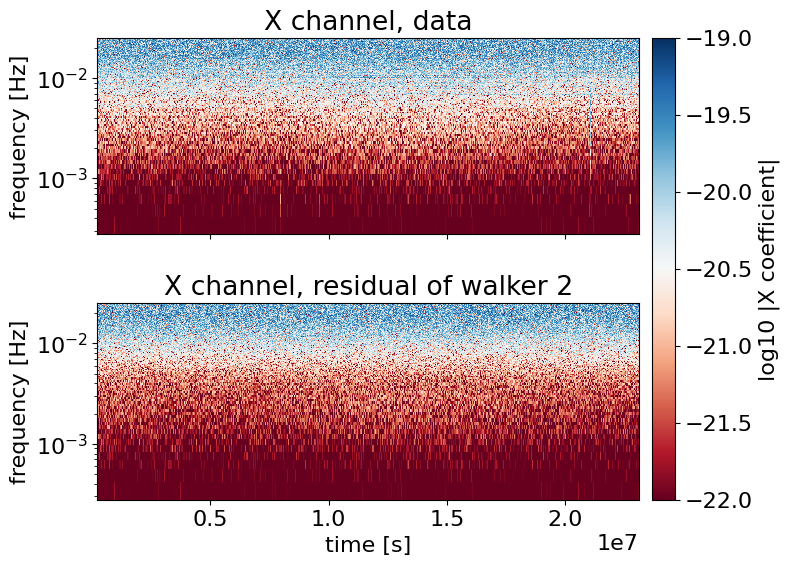

In [5]:
plt.rcParams.update({"text.usetex": False})
settings = reader.read_domain_settings()
data = WDMSignal(snap["data"].astype(np.float64), settings)
residual = WDMSignal(snap["residuals"][w].astype(np.float64), settings)
fig, axes = plt.subplots(2, 1, sharex=True, sharey=True, figsize=(9, 6))
for ax, signal, label in zip(axes, [data, residual], ["data", f"residual of walker {w}"]):
    signal.heatmap(index=0, mag=True, log=True, fig=fig, ax=ax, vmin=-22, vmax=-19, rasterized=True)
    ax.set(title=f"X channel, {label}", ylabel="frequency [Hz]", yscale="log")
axes[-1].set_xlabel("time [s]")
fig.subplots_adjust(hspace=0.35)
fig.colorbar(axes[0].collections[0], ax=axes, label="log10 |X coefficient|", pad=0.02)
plt.show()

Each source section shows its template `h` with `show_source`, one figure on the X channel. The top
row holds the WDM coefficients in the region of the grid the source occupies: the data with every
other fitted signal removed (`residual + h`), the template and the residual. `wdm_panels` draws them
as the monitor page does: linear `|w|`, one colour scale shared by the three panels, topped at the
data panel's 99.5th percentile in that region. The bottom row is the template in the time domain
(`X(t)` over the whole span, drawn as the range of every few hundred samples, and `X(t)` in the window
`t_zoom`, by default two hours at the middle of the span) and in the frequency domain
($|\tilde{X}(f)|$). Both come from
one inverse WDM transform of the template's X channel, `wdm_to_fd` and then `ifft`, after the active
box is zero-padded into the full grid, so they are band-limited to the analysed band and span: the
template as the likelihood sees it. Times are in days from the data start, frequencies in mHz.

`show_template` draws a template alone, topped at the 99.5th percentile of its own non-zero pixels,
for a source whose coefficients sit far below the data's scale (the EMRI section).

`show_noise` draws the noise model of the psd and galfor sections. Left, the X-channel PSD from the
unequal-arm closed form `UnequalArmXX2TDISens` with the six link delays averaged over the run, alone
and, when `galfor` is given, with the foreground spectrum added. Its noise model is built as the
backend builds it (`backend.instrument_model_cls`); the closed form reads only the two levels, so the
model's `orbits` slot is `None`. Right, the WDM covariance `C_XX` on the active grid, on a log scale
since it spans decades, or, with `instrument` given, the foreground's part of it divided by its time
mean in every layer, which is the modulation in time the PSD cannot show.

In [6]:
def wdm_panels(axes, signals, settings, f_lim=None, t_lim=None):
    f_lim = f_lim or (settings.f_arr_edges[0], settings.f_arr_edges[-1])
    t_lim = t_lim or (settings.t_arr_edges[0], settings.t_arr_edges[-1])
    f_in = (settings.f_arr >= f_lim[0]) & (settings.f_arr <= f_lim[1])
    t_in = (settings.t_arr >= t_lim[0]) & (settings.t_arr <= t_lim[1])
    top = np.percentile(np.abs(signals[0].arr[0])[f_in][:, t_in], 99.5)
    t_e, f_e = settings.t_arr_edges / 86400, settings.f_arr_edges * 1e3
    for ax, signal in zip(axes, signals):
        im = ax.imshow(np.abs(signal.arr[0]), extent=[t_e[0], t_e[-1], f_e[0], f_e[-1]], aspect="auto",
                       origin="lower", cmap="viridis", interpolation="nearest", vmin=0, vmax=top)
        ax.set(xlim=np.array(t_lim) / 86400, ylim=np.array(f_lim) * 1e3, xlabel="time [d]")
        ax.grid(False)
    axes[0].set_ylabel("frequency [mHz]")
    plt.colorbar(im, ax=axes[-1], fraction=0.046, pad=0.02, label="|w|")


def show_source(h, residual, title, f_lim=None, t_lim=None, t_zoom=None):
    pad = np.zeros((1, settings.Nf, settings.Nt))
    pad[:, settings.active_slice_f, settings.active_slice_t] = h.arr[0:1]
    fd = WDMSignal(pad, WDMSettings(settings.Nf, settings.Nt, settings.data_dt)).wdm_to_fd()
    del pad
    td = fd.ifft()
    x, t, f = td.arr[0], td.t_arr, fd.f_arr
    n = max(1, x.size // 50000)
    blocks = x[: x.size // n * n].reshape(-1, n)
    t_mid = 0.5 * (settings.t_arr_edges[0] + settings.t_arr_edges[-1])
    t_a, t_b = t_zoom or (t_mid, t_mid + 7200)
    f_a, f_b = f_lim or (settings.f_arr_edges[0], settings.f_arr_edges[-1])
    zoom, band = (t >= t_a) & (t <= t_b), (f >= f_a) & (f <= f_b)
    fig, axes = plt.subplots(2, 3, figsize=(13, 7), layout="constrained")
    wdm_panels(axes[0], [residual + h, h, residual], settings, f_lim, t_lim)
    axes[1, 0].fill_between(t[: x.size // n * n: n] / 86400, blocks.min(axis=1), blocks.max(axis=1), lw=0)
    axes[1, 1].plot((t[zoom] - t_a) / 3600, x[zoom], lw=0.6)
    axes[1, 2].semilogy(f[band] * 1e3, np.abs(fd.arr[0, band]), lw=0.6)
    axes[1, 2].set_xscale("linear" if f_lim else "log")
    axes[1, 0].set(xlabel="time [d]", ylabel="X(t)")
    axes[1, 1].set(xlabel=f"time [h] from day {t_a / 86400:.2f}", ylabel="X(t)")
    axes[1, 2].set(xlabel="frequency [mHz]", ylabel=r"$|\tilde{X}(f)|$ [1/Hz]")
    titles = ["data: residual + h", "template h", "residual",
              "time domain, full span", "time domain, zoom", "frequency domain"]
    for ax, label in zip(axes.flat, titles):
        ax.set_title(label)
    fig.suptitle(f"X channel, {title}")
    plt.show()


def show_template(h, title, f_lim=None, t_lim=None, log_f=False):
    a = np.abs(h.arr[0])
    t_e, f_e = settings.t_arr_edges / 86400, settings.f_arr_edges * 1e3
    fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
    im = ax.imshow(a, extent=[t_e[0], t_e[-1], f_e[0], f_e[-1]], aspect="auto", origin="lower",
                   cmap="viridis", interpolation="nearest", vmin=0, vmax=np.percentile(a[a > 0], 99.5))
    ax.set(xlabel="time [d]", ylabel="frequency [mHz]", yscale="log" if log_f else "linear",
           xlim=None if t_lim is None else np.array(t_lim) / 86400,
           ylim=None if f_lim is None else np.array(f_lim) * 1e3, title=f"template h, {title}")
    ax.grid(False)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.02, label="|w|")
    plt.show()


def show_noise(sens, psd, galfor, title, instrument=None):
    f = settings.f_arr
    model = backend.instrument_model_cls(psd[0] ** 2, psd[1] ** 2, None, title)
    kw = dict(model=model, ltts=ltts.run_average())
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), layout="constrained")
    axes[0].loglog(f * 1e3, UnequalArmXX2TDISens.get_Sn(f, **kw), label="instrument")
    if galfor is not None:
        fg = dict(stochastic_params=galfor, stochastic_function=backend.galfor_stochastic_fn)
        axes[0].loglog(f * 1e3, UnequalArmXX2TDISens.get_Sn(f, **kw, **fg), label="instrument + foreground")
    axes[0].set(xlabel="frequency [mHz]", ylabel="$S_X(f)$ [1/Hz]", title="frequency domain")
    axes[0].grid(alpha=0.3, which="both")
    axes[0].legend()
    t_e, f_e = settings.t_arr_edges / 86400, settings.f_arr_edges * 1e3
    if instrument is None:
        z, label, name = np.log10(sens.sens_mat[0, 0]), "log10 C_XX", "WDM covariance"
    else:
        fg = sens.sens_mat[0, 0] - instrument.sens_mat[0, 0]
        z, label, name = fg / fg.mean(axis=1, keepdims=True), "C_XX / its time mean", "WDM covariance, foreground"
    im = axes[1].imshow(z, extent=[t_e[0], t_e[-1], f_e[0], f_e[-1]], aspect="auto", origin="lower",
                        cmap="viridis", interpolation="nearest")
    axes[1].set(xlabel="time [d]", ylabel="frequency [mHz]", title=name,
                ylim=None if instrument is None else (f_e[0], 6.0))
    axes[1].grid(False)
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.02, label=label)
    fig.suptitle(f"X channel, {title}")
    plt.show()

### More info: the layout on disk, the snapshot's limits, memory

Everything sits under the store's `global_fit` group:

| path | shape | holds |
|---|---|---|
| `chain/<branch>` | `(rows, 1, 1, nwalkers, nleaves_max, ndim)` | cold chain (`get_chain()`) |
| `inds/<branch>` | `(rows, 1, 1, nwalkers, nleaves_max)` | alive sources (`get_inds()`) |
| `log_like` | `(rows, 1, 1, nwalkers)` | joint cold log-likelihood (`get_log_like()`) |
| `key_order`, `ndims`, `nleaves_max` | attributes | sampling basis and sizes of each branch |
| `domain_settings` | group | the WDM grid (`read_domain_settings()`) |
| `noise_model_identity` | attributes | what the noise model was built from (next section) |
| `recipe/<stage>` | attributes | the stages and the rows where each started and finished |
| `sub_backend/<branch>/chain`, `inds` | `(rows, ntemps, nwalkers, nleaves_max[, ndim])` | the tempered ensemble |
| `sub_backend/<branch>/log_like` | `(rows, ntemps, nwalkers)` | log-likelihood of every rung |
| `sub_backend/<branch>/betas`, `betas_all`, `band_*` | per row | the temperature ladder: one per branch, one per source, or one per GB band |
| `sub_backend/<branch>/d_h`, `h_h` | `(rows, nwalkers, nleaves_max)` | per-source inner products, used in the source sections |

The two singleton axes of the cold datasets are the sampler and the temperature; the readers drop
the sampler axis. Datasets are allocated for the full run up front; only the first
`reader.iteration` rows are written, and every reader method stops there.

The snapshot holds ONE state, overwritten every `GF_RESIDUAL_SNAPSHOT_EVERY` rows (default 3), so
only `store_row` has a stored residual. The arrays are float32: a
log-likelihood recomputed from them matches the stored one to about a hundredth of a nat, not to
machine precision. The row check uses exact equality because these log-likelihoods are of order
1e8, where `np.allclose`'s default relative tolerance (1e-5) spans thousands of nats and accepts
neighbouring rows.

Memory: `get_chain()` reads every row of every branch. On a full production store the GB chain
alone is rows x walkers x 20000 x 9 doubles (11 GB for 2000 rows and 4 walkers), so read one row with
`get_a_sample(row)`, one branch with `get_chain(branch_names=[name])`, or a range of rows with
`get_value("chain", slice_vals=slice(a, b))`; the sub-backends take the same `slice_vals`
(`reader.sub_backend[name].get_value("chain", slice_vals=...)`).

## The instrument noise (psd)

The `psd` branch samples the two instrument noise levels, `Soms_d` (optical metrology) and `Sa_a`
(test-mass acceleration), one entry per walker. With the `galfor` foreground they set the noise
covariance every source is scored against. This section reads them, rebuilds that covariance from
the store's noise-model identity record, and recomputes the stored log-likelihood.

Soms_d, Sa_a of walker 2 at row 1684 : [1.49986126e-11 3.08555508e-15]


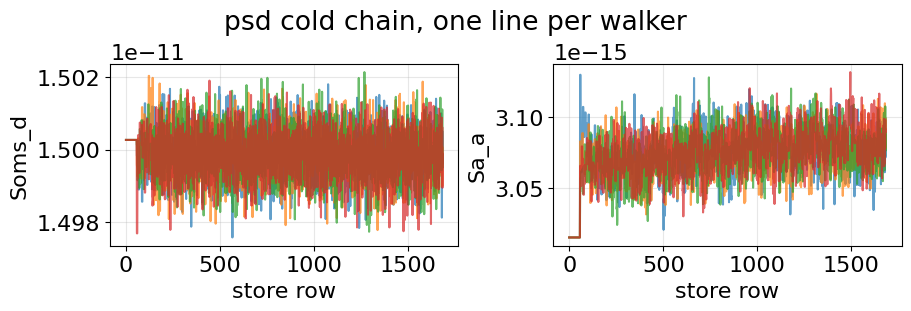

In [7]:
print("Soms_d, Sa_a of walker", w, "at row", row, ":", state.branches_coords["psd"][0, w, 0])
psd_chain = reader.get_chain(branch_names=["psd"])["psd"][:, 0, :, 0]
fig, axes = plt.subplots(1, 2, figsize=(9, 3), layout="constrained")
for i, label in enumerate(["Soms_d", "Sa_a"]):
    axes[i].plot(psd_chain[:, :, i], alpha=0.7)
    axes[i].set_xlabel("store row")
    axes[i].set_ylabel(label)
    axes[i].grid(alpha=0.3)
fig.suptitle("psd cold chain, one line per walker")
plt.show()

Stages that hold the noise fixed leave this trace flat. The tempered information is the psd move's
own temperature ladder, `state.sub_states["psd"]`: `coords` is `(ntemps, nwalkers, 1, 2)`, `betas`
holds the inverse temperatures, and `log_like` the `(ntemps, nwalkers)` log-likelihood of every
rung. 

In [8]:
psd_sub = state.sub_states["psd"]
print("coords", psd_sub.coords.shape, " log_like", psd_sub.log_like.shape)
print("betas", psd_sub.betas)
print("log_like of walker", w, "on each rung", psd_sub.log_like[:, w])

coords (12, 4, 1, 2)  log_like (12, 4)
betas [1.         0.59194648 0.35043556 0.20814661 0.12318609 0.07274781
 0.04308218 0.02563309 0.01511315 0.00890718 0.004309   0.        ]
log_like of walker 2 on each rung [1.58054897e+08 1.58054897e+08 1.58054894e+08 1.58054889e+08
 1.58054887e+08 1.58054890e+08 1.58054893e+08 1.58054842e+08
 1.58054803e+08 1.58054660e+08 1.58054664e+08 1.57991905e+08]


The model is a `CompositeSensitivityBackend`. Called with one walker's noise parameters, it returns
that walker's `CompositeSensitivityMatrix`: the 3x3 XYZ covariance of every WDM pixel, the sum of an
instrument component and a galactic-foreground component. Production runs use
`UnequalArmInstrumentNoise`, TDI-2 noise with the six link delays of the real orbit, averaged over
each WDM time column, so the covariance changes as the arms breathe. The foreground is modulated in
time by `GalForTimeModulation`, as the galaxy's signal rises and falls with the constellation's
orientation. The basic sensitivity matrix is in [`04`](04_Foundations.ipynb) §"Sensitivity".

The run records which pieces it used in a **noise-model identity** record in the store: the
instrument class, the WDM PSD method, the data epoch `data_t0` that aligns the delay and
modulation tables with the WDM grid, and the sampling basis of each noise branch. The backend is
rebuilt from it.

In [9]:
ident = read_noise_model_identity(store)
ident

{'coarse_Q': 1,
 'coarse_mode': 'off',
 'coarse_use_ws': True,
 'data_t0': 97729939.827664,
 'galfor_log_sampling': True,
 'galfor_modulation': 'modulation_unequal.dat',
 'galfor_modulation_digest': '2fd5af9aaf893724',
 'galfor_modulation_t0': 97729939.827664,
 'instrument_component': 'UnequalArmInstrumentNoise',
 'ltts_digest': 'f1f3f00ea5d9cf13',
 'psd_log_sampling': False,
 'unequal_arm': True,
 'wdm_psd_method': 'layer_calibrated'}

`resolve_noise_file` finds the mojito L1 NOISE brick in the mojito data folder (the cache the data
loader fills); only its `/ltts` group is read. The foreground modulation table ships with the
lisatools package (`lisatools/galfor_modulation/`), and the store records its file name, which
`GalForTimeModulation` resolves to that packaged copy. The stride, one
delay sample in 200, is the production `UNEQUAL_ARM_STRIDE`.

In [10]:
mojito_dir = os.path.expanduser("~/.mojito_cache/brickmarket/mojito_light_v1_0_0")
modulation_file = ident["galfor_modulation"]  # a bare name: the table packaged with lisatools
ltts = LinkDelayTable.from_l1_file(resolve_noise_file(mojito_dir), stride=200, data_t0=ident["data_t0"])
backend = CompositeSensitivityBackend(
    settings, tdi_generation=2,
    instrument_component_cls=UnequalArmInstrumentNoise,
    instrument_component_kwargs=dict(ltts=ltts),
    wdm_psd_method=ident["wdm_psd_method"],
    galfor_modulation=GalForTimeModulation(modulation_file, t0=ident["galfor_modulation_t0"]),
)

Each branch's row goes from its sampling basis to the model's parameters before the call; the
identity record says which basis each noise branch used. Production runs sample `psd` linearly
(`psd_log_sampling` False, no transform) and `galfor` in log10 (`galfor_log_sampling` True, through
`make_galfor_log_transform_container()`, explained in the galfor section).

`sens` is the full noise model of walker `w`; `sens_instrument`, built without `galfor_params`, is
its instrument part alone. The figure (`show_noise`) shows the instrument part on the X channel: its
PSD in the frequency domain, and its WDM covariance `C_XX`, which changes from column to column as
the arms breathe.

psd (Soms_d, Sa_a): [1.49986126e-11 3.08555508e-15]
galfor (amp, fk, alpha, f_1, f_2): [1.30020786e-44 7.20412233e-03 2.30426892e+00 2.33303802e-03
 1.47797521e-03]


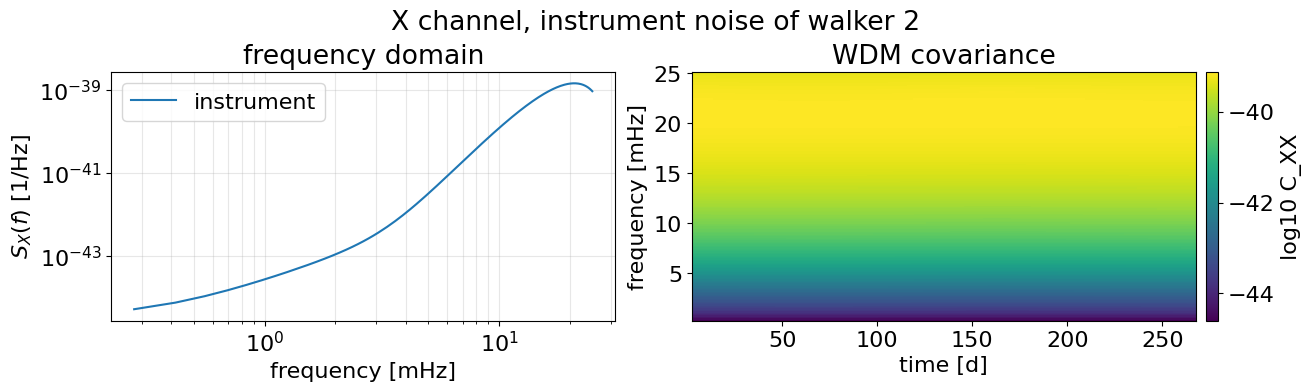

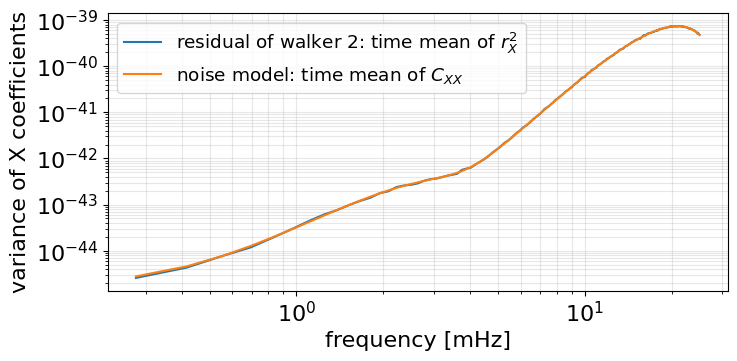

In [11]:
galfor_transform = make_galfor_log_transform_container()
psd = state.branches_coords["psd"][0, w, 0]
galfor = galfor_transform.both_transforms(state.branches_coords["galfor"][0, w, 0])
sens = backend(f"walker_{w}", psd, galfor_params=galfor)
sens_instrument = backend(f"walker_{w}_instrument", psd)
print("psd (Soms_d, Sa_a):", psd)
print("galfor (amp, fk, alpha, f_1, f_2):", galfor)
show_noise(sens_instrument, psd, None, f"instrument noise of walker {w}")
plt.figure(figsize=(8, 3.6))
plt.loglog(settings.f_arr * 1e3, (residual.arr[0] ** 2).mean(axis=-1), label=f"residual of walker {w}: time mean of $r_X^2$")
plt.loglog(settings.f_arr * 1e3, sens.sens_mat[0, 0].mean(axis=-1), label="noise model: time mean of $C_{XX}$")
plt.xlabel("frequency [mHz]")
plt.ylabel("variance of X coefficients")
plt.grid(alpha=0.3, which="both")
plt.legend(loc="upper left", fontsize="small")
plt.show()

The second figure compares the time-averaged covariance of the full model with the residual's
time-averaged power layer by layer: where the residual sits above the model, power is left unfit;
where it sits below, the noise model is too loud.

In the real WDM basis the log-likelihood is `-1/2 sum r C^-1 r - 1/2 sum log det C` over the pixels.
Scoring the residual with the rebuilt covariance `sens` gives back the stored cold log-likelihood of
walker `w` (same row, same walker), up to the float32 rounding of the snapshot.
`likelihood(noise_only=True)` is the normalization term `-1/2 sum log det C`.

In [12]:
ac = AnalysisContainer(residual, sens)
lnl = ac.likelihood()
print("rebuilt log-likelihood:", lnl)
print("stored, store row     :", state.log_like[0, w])
print("stored, snapshot      :", snap["lnl"][w])
print("rebuilt - stored      :", lnl - state.log_like[0, w])
print("noise-only term       :", ac.likelihood(noise_only=True))

rebuilt log-likelihood: 158054869.1941222
stored, store row     : 158054869.19136453
stored, snapshot      : 158054869.19136453
rebuilt - stored      : 0.0027576684951782227
noise-only term       : 159762333.58002508


## The galactic foreground (galfor)

The `galfor` branch samples the confusion noise of the unresolvable galactic binaries,
one entry per walker. Its five parameters set the spectrum of `HyperbolicTangentGalacticForeground`,
$S(f) = \frac{A}{2} f^{-7/3} e^{-(f/f_1)^\alpha} [1 + \tanh((f_k - f)/f_2)]$, which
`GalForTimeModulation` modulates in time. Production runs sample the amplitude and the three
frequencies as log10 and `alpha` linearly; `make_galfor_log_transform_container()` maps a stored row
to the model's values, and its `input_basis` names the stored columns.

In [13]:
print(galfor_transform.input_basis, state.branches_coords["galfor"][0, w, 0])
print(galfor_transform.output_basis, galfor)
galfor_sub = state.sub_states["galfor"]
print("betas", galfor_sub.betas)
print("log_like of walker", w, "on each rung, minus the cold rung:", galfor_sub.log_like[:, w] - galfor_sub.log_like[0, w])

['log10_amp', 'log10_fk', 'alpha', 'log10_f_1', 'log10_f_2'] [-43.88598721  -2.14241892   2.30426892  -2.63207818  -2.83033285]
['amp', 'fk', 'alpha', 'f_1', 'f_2'] [1.30020786e-44 7.20412233e-03 2.30426892e+00 2.33303802e-03
 1.47797521e-03]
betas [1.         0.72703161 0.5299378  0.38180119 0.27286152 0.19645394
 0.14160257 0.10159277 0.07323246 0.05156844 0.03248914 0.        ]
log_like of walker 2 on each rung, minus the cold rung: [ 0.00000000e+00 -6.74026316e+00 -8.58317775e+00 -7.33051491e+00
 -1.21540284e+01 -5.39283273e+00 -3.09496571e+01 -2.79337722e+01
 -2.14738467e+01 -2.22710555e+01 -8.06754138e+01 -9.83877251e+04]


The foreground is one component of the psd section's `backend`: `sens` includes it and
`sens_instrument` does not. The figure is the psd section's with the foreground added: the
frequency-domain panel adds the instrument + foreground PSD (the foreground spectrum through the
X-channel TDI-2 response, without its time modulation), and the WDM panel shows the foreground's part of
`C_XX` (`sens` minus `sens_instrument`) divided by its time mean in every layer: the modulation in
time, as the galaxy's signal rises and falls with the constellation's orientation.

/var/folders/c0/p4f73hs11yz45_z7gqw3f5gw0000gn/T/ipykernel_19836/2545006336.py:78: RuntimeWarning: invalid value encountered in divide
  z, label, name = fg / fg.mean(axis=1, keepdims=True), "C_XX / its time mean", "WDM covariance, foreground"


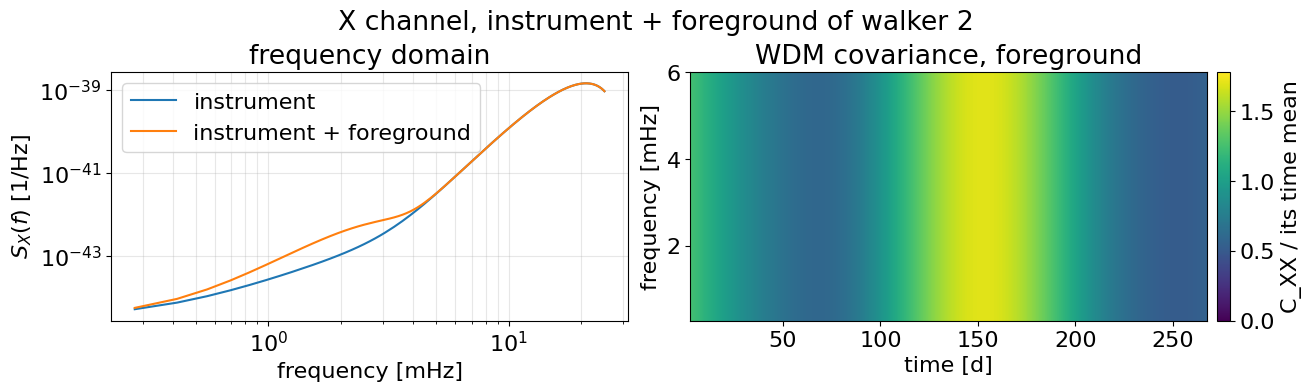

log-likelihood with the foreground   : 158054869.1941222


In [14]:
show_noise(sens, psd, galfor, f"instrument + foreground of walker {w}", instrument=sens_instrument)
print("log-likelihood with the foreground   :", AnalysisContainer(residual, sens).likelihood())

## Galactic binaries (gb)

The `gb` branch fits thousands of galactic binaries, each a source with the nine columns of
`reader.key_order["gb"]` (`f0` in mHz). Each source section follows one pattern: take the loudest
source `k` on walker `w` by the `<h|h>` the run stored for it, read its tempered information, map it
through the branch's transform, generate its template on the run's WDM grid, and score it against
the residual with the psd section's `sens`.

In [15]:
gb_sub = state.sub_states["gb"]
k = np.nanargmax(gb_sub.h_h[w])
print(state.branches_inds["gb"][0, w].sum(), "sources alive on walker", w, "  loudest: source", k)
for name, value in zip(reader.key_order["gb"], state.branches_coords["gb"][0, w, k]):
    print(f"{name:>16s} {value: .6g}")

3392 sources alive on walker 2   loudest: source 2739
            dist  0.823863
              f0  5.16798
              Mc  0.385466
            phi0  1.83275
        cos_iota -0.670192
             psi  0.031514
           alpha  2.03224
       sin_delta -0.899527
fdot_astro_ratio  3.16341


GB tempering runs per frequency band, each band with its own temperature ladder.
`gb_sub.band_info` holds the band edges, the inverse temperatures of every band's ladder
(`band_temps`, bands x rungs) and the number of sources on every rung of every band
(`band_num_binaries`, rungs x walkers x bands); its per-row arrays keep a leading row axis of
length one. The tempered chain itself (`gb_sub.coords`) is the cold chain times the number of
rungs; these summaries are what to read. The figure shows the cold rung's sources per band.

1232 bands; inverse temperatures of source k's band: [1.00000000e+00 7.96117333e-01 6.97976373e-01 5.48225007e-01
 4.77064890e-01 3.81253057e-01 3.30229801e-01 2.65847801e-01
 2.32890849e-01 1.83431941e-01 1.58956989e-01 1.27984655e-01
 1.12830524e-01 8.78119589e-02 7.81793826e-02 5.98543410e-02
 5.34520040e-02 4.09800123e-02 3.62838711e-02 2.85377890e-02
 2.48466867e-02 2.01375928e-02 1.69896419e-02 1.00000000e-04]
sources per rung on walker 2 : [3392. 3172. 3096. 2691. 2468. 2094. 1909. 1651. 1529. 1350. 1244. 1065.
 1061.  923.  916.  893.  910.  938. 1063. 1114. 1154. 1386. 1432. 4423.]


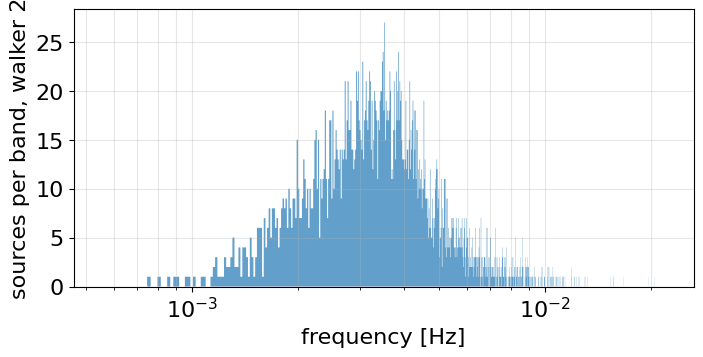

In [16]:
band_info = gb_sub.band_info
band = np.searchsorted(band_info["band_edges"], 1e-3 * state.branches_coords["gb"][0, w, k, 1]) - 1
print(len(band_info["band_edges"]) - 1, "bands; inverse temperatures of source k's band:", band_info["band_temps"][0, band])
print("sources per rung on walker", w, ":", band_info["band_num_binaries"][0, :, w].sum(axis=-1))
plt.figure(figsize=(8, 3.6))
plt.stairs(band_info["band_num_binaries"][0, 0, w], band_info["band_edges"], fill=True, alpha=0.7)
plt.xscale("log")
plt.grid(alpha=0.3, which="both")
plt.xlabel("frequency [Hz]")
plt.ylabel(f"sources per band, walker {w}")
plt.show()

The stock transform `make_gb_transform_container(use_chirp_mass=True, use_fdot_astro=True,
use_distance=True)` maps the stored columns to the generator's nine physical parameters: the
amplitude from distance, `f0` and `Mc`; `f0` in Hz; `fdot` from the GR chirp of `Mc` times
`1 + fdot_astro_ratio`; `fddot` = 0; the sign-flipped `phi0`; the inclination; `psi`; and the ICRS
sky as right ascension and declination. The output columns keep the sampling names: `cos_iota`
holds the inclination and `sin_delta` the declination.

In [17]:
gb_transform = make_gb_transform_container(use_chirp_mass=True, use_fdot_astro=True, use_distance=True)
print("input basis matches the store:", list(gb_transform.input_basis) == list(reader.key_order["gb"]))
gb_k = gb_transform.both_transforms(state.branches_coords["gb"][0, w, k])
for name, value in zip(gb_transform.output_basis, gb_k):
    print(f"{name:>10s} {value: .6g}")

input basis matches the store: True
         A  4.40236e-22
        f0  0.00516798
      fdot  2.0326e-15
     fddot  0
      phi0 -1.83275
  cos_iota  2.30526
       psi  0.031514
     alpha  2.03224
 sin_delta -1.11869


Every source's response uses the run's orbits: `L1Orbits` reads the spacecraft positions and the
six link delays from the same L1 noise brick in the ICRS frame the run samples in. The brick
tabulates the link delays every 2.5 s for two years (1.2 GB); they change over months, so
`ltt_stride=200` reads one sample in 200, as the noise model does. The source sections below reuse
these `orbits`.

In [18]:
orbits = L1Orbits(resolve_noise_file(mojito_dir), frame="icrs", ltt_stride=200)

The run's GB comp is `GBLookupWDMComputations` (gbgpu): a `GBWDMComputations` (the chunked-heterodyne
template: a binary's TDI-2 XYZ response computed directly on the WDM grid, heterodyned around the
source's frequency in chunks) whose per-row likelihood `get_ll_wdm` is the lookup scorer. The scorer
reads each row's WDM coefficients straight from the GB WDM lookup table, at one carrier
`(f_ref, fdot_ref)` common to the X, Y and Z channels plus an amplitude-slope term, with no heterodyne
reference; `resolve_gb_lookup_table(table_dir=run_dir)` finds the table in the run folder, or builds
it there. The in-model moves score every proposal with `GBSignalHetComputations`,
the signal-heterodyne (sig-het) engine that `for_band_engine` wraps around that comp. Sig-het makes
a block of proposals cheap: `setup_in_model` builds one reference template per source at the block's
starting parameters and folds it once with the data and the inverse covariance into a few moments;
a proposal then enters only through its smooth ratio to the reference, fitted on a few spline nodes
inside one kernel call, which gives its `<d|h>` and `<h|h>` without building its template. With the
table attached, the reference's coefficients, the anchor that pins its frequency and the information
matrix behind the proposals come from the table too, through a `GBLookupComputations` inside the
engine (`anchor_engine="lookup"`).

RJ births and removals and any score outside an in-model block use the lookup scorer (the engine's
`get_ll_wdm` falls back to the comp's when no reference is active), and with `lookup_fill` the
template added to or removed from the residual is the lookup template too, so the residual only ever
holds templates the likelihood scored; in-model proposals use sig-het; swaps and the F-statistic's
grid scoring stay on the chunked comp. On an H100 the lookup scorer
takes about 4, 7 and 19 microseconds per row for 180, 360 and 720 days of data, against 88, 172 and
345 for the chunked template, and agrees with it to 1e-5 to 3e-5 nats in the median and at most
about 5e-3 nats. The keyword arguments below are the run's production settings. As in the run, the
comp gets a copy of the WDM grid whose `t0` is the data's absolute start time, and `t_ref` is the
epoch the catalogue parameters are defined at. `fill_global_wdm` adds the lookup template into a
zeroed `WDMSignal`.

In [19]:
gb_settings = WDMSettings(*settings.args, **{**settings.kwargs, "t0": ident["data_t0"]})
gb_table = resolve_gb_lookup_table(table_dir=run_dir)
gb_comp = GBLookupWDMComputations(gb_settings, t_ref=MOJITO_REFERENCE_TIME, Nt_sub=256, n_pad=32,
                                  N_sparse=256, N_cp_sig=48, N_cp_orbit=32, orbits=orbits,
                                  tdi_config="2nd generation", tdi_type="XYZ", lookup_table=gb_table,
                                  lookup_fill=True)
gb_engine = GBSignalHetComputations.for_band_engine(
    gb_comp, nt_layer=180, n_sparse_fd=1024, max_r=0.0, n_cp_build=256, v3_n_nodes=64, v4_knots=128,
    v4_band=16, v5=1, tukey_alpha=0.01, lookup_table=gb_table,
    anchor_engine="lookup")
h = WDMSignal(np.zeros((3, *settings.basis_shape_active)), settings)
gb_comp.fill_global_wdm(gb_k, h)

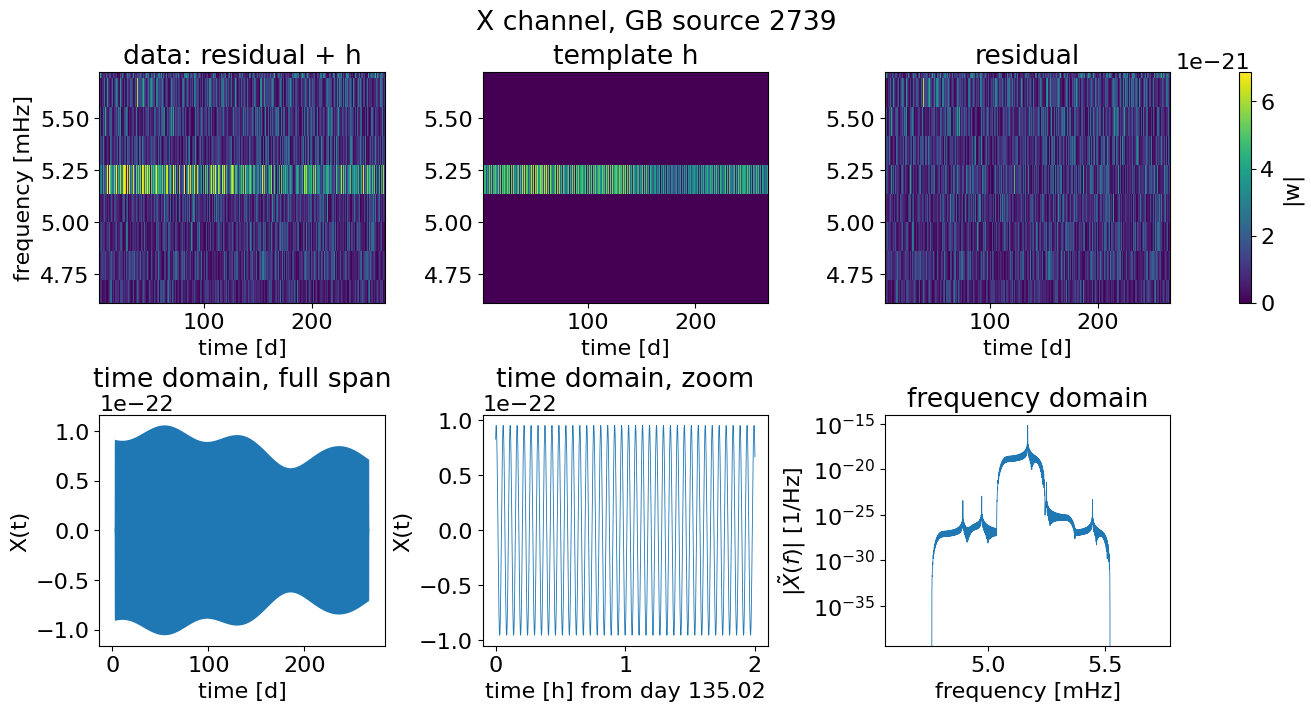

In [20]:
df = settings.f_arr[1] - settings.f_arr[0]
show_source(h, residual, f"GB source {k}", f_lim=(gb_k[1] - 4 * df, gb_k[1] + 4 * df))

`d = residual + h` is the data with every other fitted signal removed. The engine scores a source
against a buffer holding `d` and the noise model: `setup_in_model` builds the heterodyne reference
at the source's parameters, and `get_ll_wdm` leaves `<d|h>` and `<h|h>` (the squared optimal SNR)
in `d_h_out` and `h_h_out`; the source adds `<d|h> - <h|h>/2` to the log-likelihood. The exact
template's inner products from `AnalysisContainer` are the check on the engine. `gb_comp.get_ll_wdm`
on the same buffer is the lookup scorer, which the run uses for every score outside an in-model
block; its `<d|h>` and `<h|h>` (in `gb_comp.d_h_out` and `gb_comp.h_h_out`) are printed beside the
engine's and the exact template's. The run stores the same two numbers for every source
(`gb_sub.d_h`, `gb_sub.h_h`) from its last in-model block, scored against the residual and the
noise covariance of that moment in the iteration; the other moves of the row shift both by a few
parts in 1e4 (the psd walkers alone move `<h|h>` by about 1e-3 per row), so at the snapshot's row
the stored values agree to that level rather than exactly. At any other row the residual belongs to
a different state and the gap in `<d|h>` grows.

In [21]:
buffer = AnalysisContainerArray(AnalysisContainer(residual + h, sens))
gb_engine.setup_in_model(buffer, gb_k[None], np.array([0]))
gb_engine.get_ll_wdm(gb_k[None], buffer, data_index=np.array([0]))
h_h, d_h = float(gb_engine.h_h_out[0]), float(gb_engine.d_h_out[0])
gb_engine.clear_in_model()
gb_comp.get_ll_wdm(gb_k[None], buffer, data_index=np.array([0]))
ac = AnalysisContainer(residual + h, sens)
print(f"<h|h> sig-het {h_h:12.2f}   lookup {float(gb_comp.h_h_out[0]):12.2f}   "
      f"exact template {ac.template_snr(h)[0] ** 2:12.2f}   stored {gb_sub.h_h[w, k]:12.2f}")
print(f"<d|h> sig-het {d_h:12.2f}   lookup {float(gb_comp.d_h_out[0]):12.2f}   "
      f"exact template {ac.template_inner_product(h):12.2f}   stored {gb_sub.d_h[w, k]:12.2f}")
print(f"optimal SNR {h_h ** 0.5:.1f}, log-likelihood contribution {d_h - h_h / 2:.1f}")

<h|h> sig-het    103658.93   lookup    103657.14   exact template    103657.14   stored    103616.58
<d|h> sig-het    103567.47   lookup    103566.57   exact template    103566.57   stored    103545.50
optimal SNR 322.0, log-likelihood contribution 51738.0


## Verification galactic binaries (vgb)

The `vgb` branch fits the known verification binaries. Their frequency and sky position come from
the VGB catalogue and stay fixed, so each source samples six columns: `dist, phi0, cos_iota, psi,
Mc, fdot_astro_ratio`. The branch has its own transform: the GB container on those six inputs, with
one fill per source for `f0`, `alpha` and `sin_delta`. The template comp and the scoring engine are the gb section's `gb_comp` and `gb_engine`: the run builds the VGB branch's own, of the same classes, with the same settings and the same lookup table.

In [22]:
vgb_sub = state.sub_states["vgb"]
k = np.nanargmax(vgb_sub.h_h[w])
vgb_basis = ["dist", "phi0", "cos_iota", "psi", "Mc", "fdot_astro_ratio"]
print(state.branches_inds["vgb"][0, w].sum(), "sources alive on walker", w, "  loudest: source", k)
for name, value in zip(vgb_basis, state.branches_coords["vgb"][0, w, k]):
    print(f"{name:>16s} {value: .6g}")
print("tempered coords", vgb_sub.coords.shape, "  band ladders", vgb_sub.band_info["band_temps"][0].shape)

55 sources alive on walker 2   loudest: source 9
            dist  1.25408
            phi0  4.73661
        cos_iota  0.603448
             psi  1.18546
              Mc  0.614099
fdot_astro_ratio  0.00337942
tempered coords (8, 4, 55, 6)   band ladders (58, 8)


`gb_catalogue_to_sampling_basis` turns the catalogue into rows of the 8-column GB basis
`ln A, f0 [mHz], fdot, phi0, cos_iota, psi, alpha, sin_delta`, in the run's source order; columns
1, 6 and 7 are the fills. `both_transforms` takes `leaf_inds` to pick each row's fills.

In [23]:
rows = gb_catalogue_to_sampling_basis(load_vgb_catalogue_file(mojito_dir)["vgb"])
vgb_transform = make_gb_transform_container(
    use_chirp_mass=True, use_fdot_astro=True, use_distance=True,
    input_basis=vgb_basis,
    fill_dict=[{"f0": r[1], "alpha": r[6], "sin_delta": r[7]} for r in rows])
vgb_k = vgb_transform.both_transforms(state.branches_coords["vgb"][0, w, k][None], leaf_inds=np.array([k]))[0]
for name, value in zip(vgb_transform.output_basis, vgb_k):
    print(f"{name:>10s} {value: .6g}")

         A  3.27522e-22
        f0  0.00194414
      fdot  2.95334e-17
     fddot  0
      phi0 -4.73661
  cos_iota  0.922979
       psi  1.18546
     alpha  3.29392
 sin_delta  0.656748


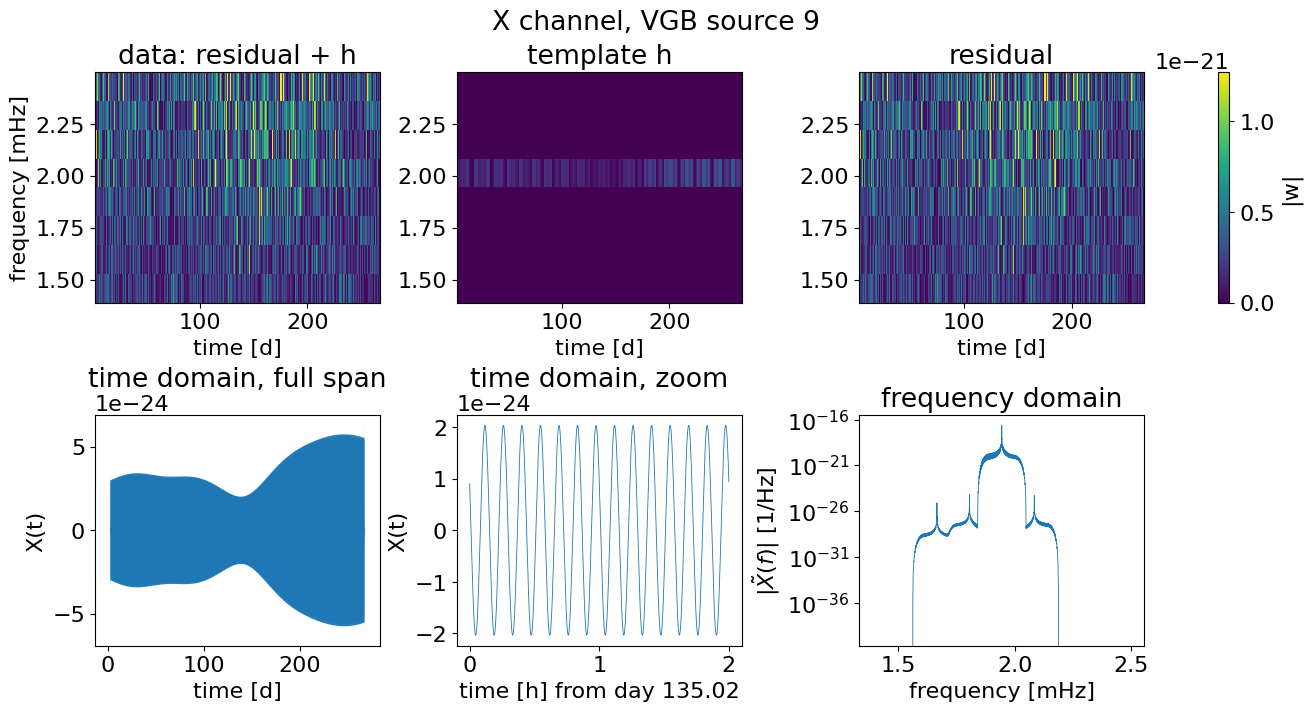

In [24]:
h = WDMSignal(np.zeros((3, *settings.basis_shape_active)), settings)
gb_comp.fill_global_wdm(vgb_k, h)
show_source(h, residual, f"VGB source {k}", f_lim=(vgb_k[1] - 4 * df, vgb_k[1] + 4 * df))

In [25]:
buffer = AnalysisContainerArray(AnalysisContainer(residual + h, sens))
gb_engine.setup_in_model(buffer, vgb_k[None], np.array([0]))
gb_engine.get_ll_wdm(vgb_k[None], buffer, data_index=np.array([0]))
h_h, d_h = float(gb_engine.h_h_out[0]), float(gb_engine.d_h_out[0])
gb_engine.clear_in_model()
gb_comp.get_ll_wdm(vgb_k[None], buffer, data_index=np.array([0]))
print(f"<h|h> sig-het {h_h:12.2f}   lookup {float(gb_comp.h_h_out[0]):12.2f}   "
      f"stored {vgb_sub.h_h[w, k]:12.2f}")
print(f"<d|h> sig-het {d_h:12.2f}   lookup {float(gb_comp.d_h_out[0]):12.2f}   "
      f"stored {vgb_sub.d_h[w, k]:12.2f}")
print(f"optimal SNR {h_h ** 0.5:.1f}, log-likelihood contribution {d_h - h_h / 2:.1f}")

<h|h> sig-het      2655.37   lookup      2655.06   stored      2656.12
<d|h> sig-het      2568.36   lookup      2568.20   stored      2568.74
optimal SNR 51.5, log-likelihood contribution 1240.7


## Massive black-hole binaries (mbh)

The `mbh` branch samples each merger in the eleven columns of `reader.key_order["mbh"]`: log total
mass, mass ratio `Q = m1/m2`, aligned spins, distance in Gpc, phase, `cos_iota`, polarization, ICRS
sky, and the merger time `t_plunge` counted from `MOJITO_REFERENCE_TIME`. Each source has its own
temperature ladder.

In [26]:
mbh_sub = state.sub_states["mbh"]
k = np.nanargmax(mbh_sub.h_h[w])
print(state.branches_inds["mbh"][0, w].sum(), "sources alive on walker", w, "  loudest: source", k)
print("tempered coords", mbh_sub.coords.shape, "  log_like", mbh_sub.log_like.shape)
print("inverse temperatures of source", k, ":", mbh_sub.betas_all[k])
print("log_like of walker", w, "on each rung, minus the cold rung:", mbh_sub.log_like[k, :, w] - mbh_sub.log_like[k, 0, w])

6 sources alive on walker 2   loudest: source 2
tempered coords (8, 4, 6, 11)   log_like (6, 8, 4)
inverse temperatures of source 2 : [1.         0.72578931 0.52073058 0.37258001 0.26724379 0.19186636
 0.13976397 0.1       ]
log_like of walker 2 on each rung, minus the cold rung: [  0.          -0.45167357  -9.12921596   0.18388921  -4.05205247
 -44.17230859 -51.22560358 -38.93296519]


`make_mbh_transform_container()` maps each stored column to the generator's argument in the same
position: `m1, m2` (solar masses), `s1z, s2z`, distance in Mpc, `phi_ref`, inclination, `psi`,
right ascension, declination and the merger time.

In [27]:
mbh_transform = make_mbh_transform_container()
mbh_k = mbh_transform.both_transforms(state.branches_coords["mbh"][0, w, k])
for name, stored, value in zip(mbh_transform.input_basis, state.branches_coords["mbh"][0, w, k], mbh_k):
    print(f"{name:>9s} {stored: .6g}  ->  {value: .6g}")

     logM  14.6374  ->   1.28038e+06
        Q  1.2877  ->   994319
      s1z  0.769644  ->   0.769644
      s2z  0.939204  ->   0.939204
     dist  25.3773  ->   25377.3
  phi_ref  6.23554  ->   6.23554
 cos_iota -0.31174  ->   1.88782
      psi  0.369604  ->   0.369604
    alpha  5.30089  ->   5.30089
sin_delta -0.280024  ->  -0.283819
 t_plunge  2.27895e+07  ->   2.27895e+07


`PhenomTHMTDIWaveform` generates the IMRPhenomTHM waveform with its higher modes over a one-month
window ending after the merger, applies the TDI-2 response, and moves the result onto the WDM grid
(`get_signals_for_residuals`). A bare instance carries the stock waveform configuration; the
run-specific arguments are the epoch of `t_plunge`, the data's time grid, the orbits and the WDM
settings. The run scores MBHs with a batched, windowed version of the same model.

In [28]:
mbh_gen = PhenomTHMTDIWaveform(
    waveform_t0=MOJITO_REFERENCE_TIME,
    data_td_settings=TDSettings(settings.Nf * settings.Nt, settings.data_dt, t0=ident["data_t0"]),
    sampling_frequency=1 / settings.data_dt,
    orbits=orbits,
    output_domain_settings=settings,
)
h = mbh_gen.get_signals_for_residuals(*mbh_k)

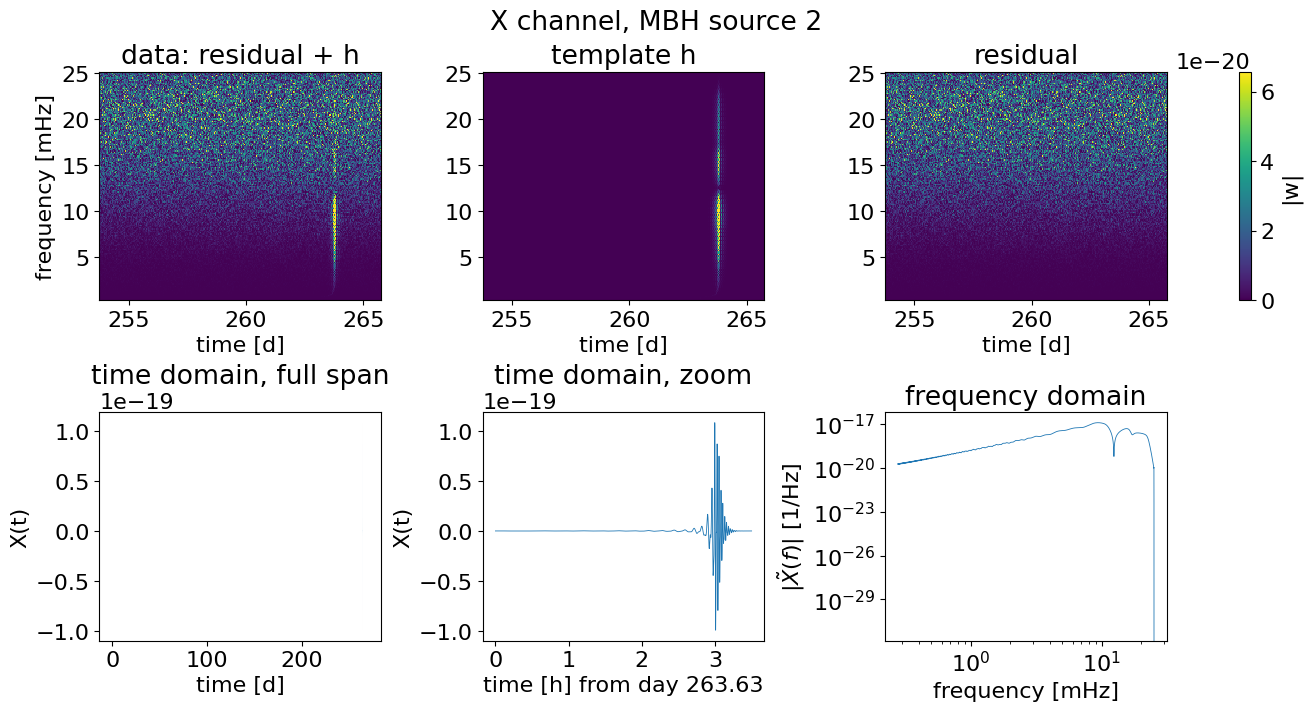

In [29]:
t_c = mbh_k[-1] + MOJITO_REFERENCE_TIME - ident["data_t0"]
show_source(h, residual, f"MBH source {k}", t_lim=(t_c - 10 * 86400, t_c + 2 * 86400),
            t_zoom=(t_c - 3 * 3600, t_c + 1800))

In [30]:
ac = AnalysisContainer(residual + h, sens)
h_h, d_h = ac.template_snr(h)[0] ** 2, ac.template_inner_product(h)
print(f"<h|h> {h_h:12.2f}   stored {mbh_sub.h_h[w, k]:12.2f}")
print(f"<d|h> {d_h:12.2f}   stored {mbh_sub.d_h[w, k]:12.2f}")
print(f"optimal SNR {h_h ** 0.5:.1f}, log-likelihood contribution {d_h - h_h / 2:.1f}")

<h|h>   1104240.16   stored   1104240.60
<d|h>   1106555.94   stored   1106647.16
optimal SNR 1050.8, log-likelihood contribution 554435.9


## Stellar-origin black-hole binaries (sobbh)

The `sobbh` branch samples stellar-mass binaries years before their merger, in the eleven columns
of `reader.key_order["sobbh"]`: log masses, spins, distance in Gpc, `cosinc`, `f_low` (the GW
frequency at `MOJITO_REFERENCE_TIME`), right ascension, sin(declination), polarization and phase.
Each source has its own temperature ladder.

In [ ]:
sobbh_sub = state.sub_states["sobbh"]
k = np.nanargmax(sobbh_sub.h_h[w])
print(state.branches_inds["sobbh"][0, w].sum(), "sources alive on walker", w, "  loudest: source", k)
print("tempered coords", sobbh_sub.coords.shape, "  log_like", sobbh_sub.log_like.shape)
print("inverse temperatures of source", k, ":", sobbh_sub.betas_all[k])
print("log_like of walker", w, "on each rung, minus the cold rung:", sobbh_sub.log_like[k, :, w] - sobbh_sub.log_like[k, 0, w])

`make_sobbh_transform_container()` maps each stored column to the waveform parameter in the same
position: masses, spins, distance in Gpc, inclination, `f_low`, right ascension, declination,
`psi` and `phi0`.

In [ ]:
sobbh_transform = make_sobbh_transform_container()
sobbh_k = sobbh_transform.both_transforms(state.branches_coords["sobbh"][0, w, k])
for name, stored, value in zip(sobbh_transform.input_basis, state.branches_coords["sobbh"][0, w, k], sobbh_k):
    print(f"{name:>6s} {stored: .6g}  ->  {value: .6g}")

The run builds and scores SOBBH templates with `SOBBHLookupComputations`: a batched TDI-on-the-fly
response on a sparse time grid, placed on the WDM grid through the precomputed WDM lookup table in
the run folder (`lookup_table_path(None, run_dir, ...)`, the same file the EMRI template reads; the
notebook does not build it). The keyword arguments are the run's production settings. It takes the
parameters in another order, with the distance in parsec; `SOBBHChunkedLikeMove.to_chunked_basis`
converts a transformed row.

In [ ]:
sobbh_table = WDMLookupTable.from_file(lookup_table_path(None, run_dir, settings.Nf, settings.data_dt))
sobbh_comp = SOBBHLookupComputations(
    settings, MOJITO_REFERENCE_TIME, sobbh_table, orbits=orbits, tdi_config=TDIConfig("2nd generation"),
    tdi_type="XYZ", t_obs_start=ident["data_t0"], n_grid=2048, buffer_time=5000.0, eval_dt=43200.0,
    num_m_layers=2, interp="spline", row_batch=32, kernel="kernel")
sobbh_chunked_k = SOBBHChunkedLikeMove.to_chunked_basis(sobbh_k)
h = WDMSignal(np.zeros((3, *settings.basis_shape_active)), settings)
sobbh_comp.fill_global_wdm(sobbh_chunked_k, h)

In [ ]:
show_source(h, residual, f"SOBBH source {k}", f_lim=(0.9 * sobbh_k[6], 1.3 * sobbh_k[6]))

`get_ll_wdm` scores the source against a container holding `d = residual + h` and leaves `<d|h>`
and `<h|h>` in `d_h_out` and `h_h_out`, the numbers the run stores for it.

In [ ]:
sobbh_comp.get_ll_wdm(sobbh_chunked_k, AnalysisContainer(residual + h, sens))
h_h, d_h = float(sobbh_comp.h_h_out[0]), float(sobbh_comp.d_h_out[0])
print(f"<h|h> {h_h:12.2f}   stored {sobbh_sub.h_h[w, k]:12.2f}")
print(f"<d|h> {d_h:12.2f}   stored {sobbh_sub.d_h[w, k]:12.2f}")
print(f"optimal SNR {h_h ** 0.5:.1f}, log-likelihood contribution {d_h - h_h / 2:.1f}")

## Extreme mass-ratio inspirals (emri)

The `emri` branch samples stellar-mass compact objects spiralling into massive black holes, in
twelve columns: log primary mass, secondary mass, spin `a`, semi-latus rectum `p0`, eccentricity
`e0`, distance in Gpc, the sky and spin directions (cosine of the polar angle, and azimuth) and two
orbital phases. The store's `key_order` labels columns 6 and 8 `qS` and `qK`, but they hold cos(qS)
and cos(qK); the transform's `input_basis` names them correctly. Each source has its own temperature
ladder.

In [ ]:
emri_sub = state.sub_states["emri"]
k = np.nanargmax(emri_sub.h_h[w])
print(state.branches_inds["emri"][0, w].sum(), "sources alive on walker", w, "  loudest: source", k)
print("tempered coords", emri_sub.coords.shape, "  log_like", emri_sub.log_like.shape)
print("inverse temperatures of source", k, ":", emri_sub.betas_all[k])
print("log_like of walker", w, "on each rung, minus the cold rung:", emri_sub.log_like[k, :, w] - emri_sub.log_like[k, 0, w])

`make_emri_transform_container` maps the twelve stored columns to FEW's fourteen parameters and
inserts two fixed values per source from the EMRI catalogue: `xI0`, +1 for a prograde and -1 for a
retrograde orbit, and the polar phase `Phi_theta0`. `emri_catalogue_to_waveform_basis` converts each
catalogue row, in the run's source order, to the fourteen parameters; columns 5 and 12 are the
fills. `both_transforms` takes `leaf_inds` to pick each source's fills.

In [ ]:
with h5py.File(os.path.join(mojito_dir, "catalogues", "emri_cat_mojito_lite_processed_MT.hdf5")) as f:
    emri_rows = np.array([emri_catalogue_to_waveform_basis({key: col[i] for key, col in f["Binaries"].items()})
                          for i in range(f["Binaries"]["ID"].size)])
emri_transform = make_emri_transform_container(emri_rows[:, [5, 12]])
emri_k = emri_transform.both_transforms(state.branches_coords["emri"][0, w, k][None], leaf_inds=np.array([k]))[0]
for name, stored, value in zip(emri_transform.input_basis, state.branches_coords["emri"][0, w, k], np.delete(emri_k, [5, 12])):
    print(f"{name:>9s} {stored: .6g}  ->  {value: .6g}")
print("fills: xI0", emri_k[5], "  Phi_theta0", emri_k[12])

The run's EMRI template is direct-to-WDM. `EMRIDirectWDM` takes the FEW model inside the generator
(`waveform_generator`, a `FastKerrEccentricEquatorialFlux`), integrates the inspiral with it and places each harmonic on the full WDM grid through the
run folder's lookup table (the SOBBH section's file), with the dense TDI response;
`EMRIDirectWDMSignalGen` cuts it to the run's active box. FEW is built as the run builds it
(`EMRI_INSPIRAL_KWARGS`, `EMRI_SUM_KWARGS`, `EMRI_MODE_SELECTOR_KWARGS`), and the mode-selection
threshold and the other keyword arguments are the run's production settings. Building FEW's model
takes about 6 GB of memory.

In [ ]:
few_gen = GenerateEMRIWaveform("FastKerrEccentricEquatorialFlux", return_list=False, frame="detector",
                               inspiral_kwargs=EMRI_INSPIRAL_KWARGS, sum_kwargs=EMRI_SUM_KWARGS,
                               mode_selector_kwargs=EMRI_MODE_SELECTOR_KWARGS)
emri_table = WDMLookupTable.from_file(lookup_table_path(None, run_dir, settings.Nf, settings.data_dt))
emri_direct = EMRIDirectWDM(few_gen.waveform_generator, emri_table, WDMSettings(settings.Nf, settings.Nt, settings.data_dt),
                            orbits=orbits, tdi_config=TDIConfig("2nd generation"),
                            t_start=MOJITO_REFERENCE_TIME, data_t0=ident["data_t0"], response="dense")
emri_gen = EMRIDirectWDMSignalGen(emri_direct, settings, nchannels=3, traj_workers=8,
                                  runtime_kwargs={"mode_selection_threshold": 1e-3})
h = emri_gen(*emri_k)

In [ ]:
show_source(h, residual, f"EMRI source {k}")

On the data's colour scale the EMRI's harmonics barely show. On the template's own scale each harmonic's
track across the band is visible.

In [ ]:
show_template(h, f"EMRI source {k}", log_f=True)

In [ ]:
ac = AnalysisContainer(residual + h, sens)
h_h, d_h = ac.template_snr(h)[0] ** 2, ac.template_inner_product(h)
print(f"<h|h> {h_h:12.2f}   stored {emri_sub.h_h[w, k]:12.2f}")
print(f"<d|h> {d_h:12.2f}   stored {emri_sub.d_h[w, k]:12.2f}")
print(f"optimal SNR {h_h ** 0.5:.1f}, log-likelihood contribution {d_h - h_h / 2:.1f}")